<a href="https://colab.research.google.com/github/elena-gazzini/2026_Intro_Python/blob/main/FEEDBACK_GAZZINI_ELENA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Gazzini Elena - SA26 Introduction to Scientific Programm*

# Graded reflective exercise


## 1.6) Geospatial Vector Data with geopandas
### Environmental Exercises

Q4) Have a look at the data on a map using geopandas' `.plot()` method.

Exclude Alaska and Hawaii using the NAME attribute and pandas' `.isin()` method. Specify the figsize to be 30 x 20.

Before anything, we need to code what ever was done before :

In [4]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

In [5]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

In [6]:
# Q1 Import geopandas (as gpd), pandas, and matplotlib
%matplotlib inline
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
# Q2 Read the data with the geopandas function
from pathlib import Path
from shapely.geometry import Polygon

Path("_files").mkdir(exist_ok=True)
# pas nécessaire de mettre ça car je sais que mon fichier exsite mais bon reflexe
# à avoir car ça vérifie si le fichier existe et sinon il en crée un qui conserve
# tout ce que je vais faire avec ce fichier

country = gpd.read_file(states_path)

And Q3 wasn't necessary to complete Q4.

#### What I did at first for Q4:

In [3]:
# Plot the US states (Alaska and Hawaii excluded)
excluded = ["Alaska", "Hawaii"]
flagged = country.assign(excluded=country["Alaska", "Hawaii"].isin(excluded["Alaska", "Hawaii"]))

fig, ax = plt.subplots(figsize=(30, 20))
flagged.plot(ax=ax, column="excluded", categorical=True, legend=True, markersize=40)
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Countries excluded Alaska and Hawaii")
plt.show()
plt.show()

NameError: name 'country' is not defined

Many mistakes where made here:

- `...(excluded=country["Alaska", "Hawaii"...` : here I need to specify the name of the column I want to use, not the label yet, so it has to be replaced by `...(country["NAME]"...` meaning that in the dataset `country` I select the column `"NAME"`

- then I repeating myself in the first 2 lines of code, I can just simplfy them as so `country_filtred = country.assign(country["NAME"].isin(["Alaska", "Hawaii"]))`

- then the easiest way for me is to exclude Alaska and Hawaii, is to pick them with the function `.isin` and then use the negative : `country_filtred = country(~country.assign["NAME"].isin(["Alaska", "Hawaii"]))`. `~`has to be just in front of the action, which is "is the column "NAME" of the dataset country, create a serie of booleens whee Alaska and Hawaii and `True`.

- The `.assign` can be dropped since we want to exclude Alaska et Hawaii, not create a new column with this serie: `(~country["NAME"].isin(["Alaska", "Hawaii"]))`

- the last correction is the brackets, that are correct if we use `.assign`, but incorrect if we drop it. We need to replace the first and last brackets `()` by `[]`: `country_filtred = country[~country["NAME"].isin(["Alaska", "Hawaii"])]`.


Now that this line is correct, we can plot this:

- since we didn't create a new column, that we directly excluded Hawaii and Alaska from the dataset, we can also drop `column="excluded` (since it doesn't exist and that the dataset already excluded the 2 countries).

The final code could look as so:

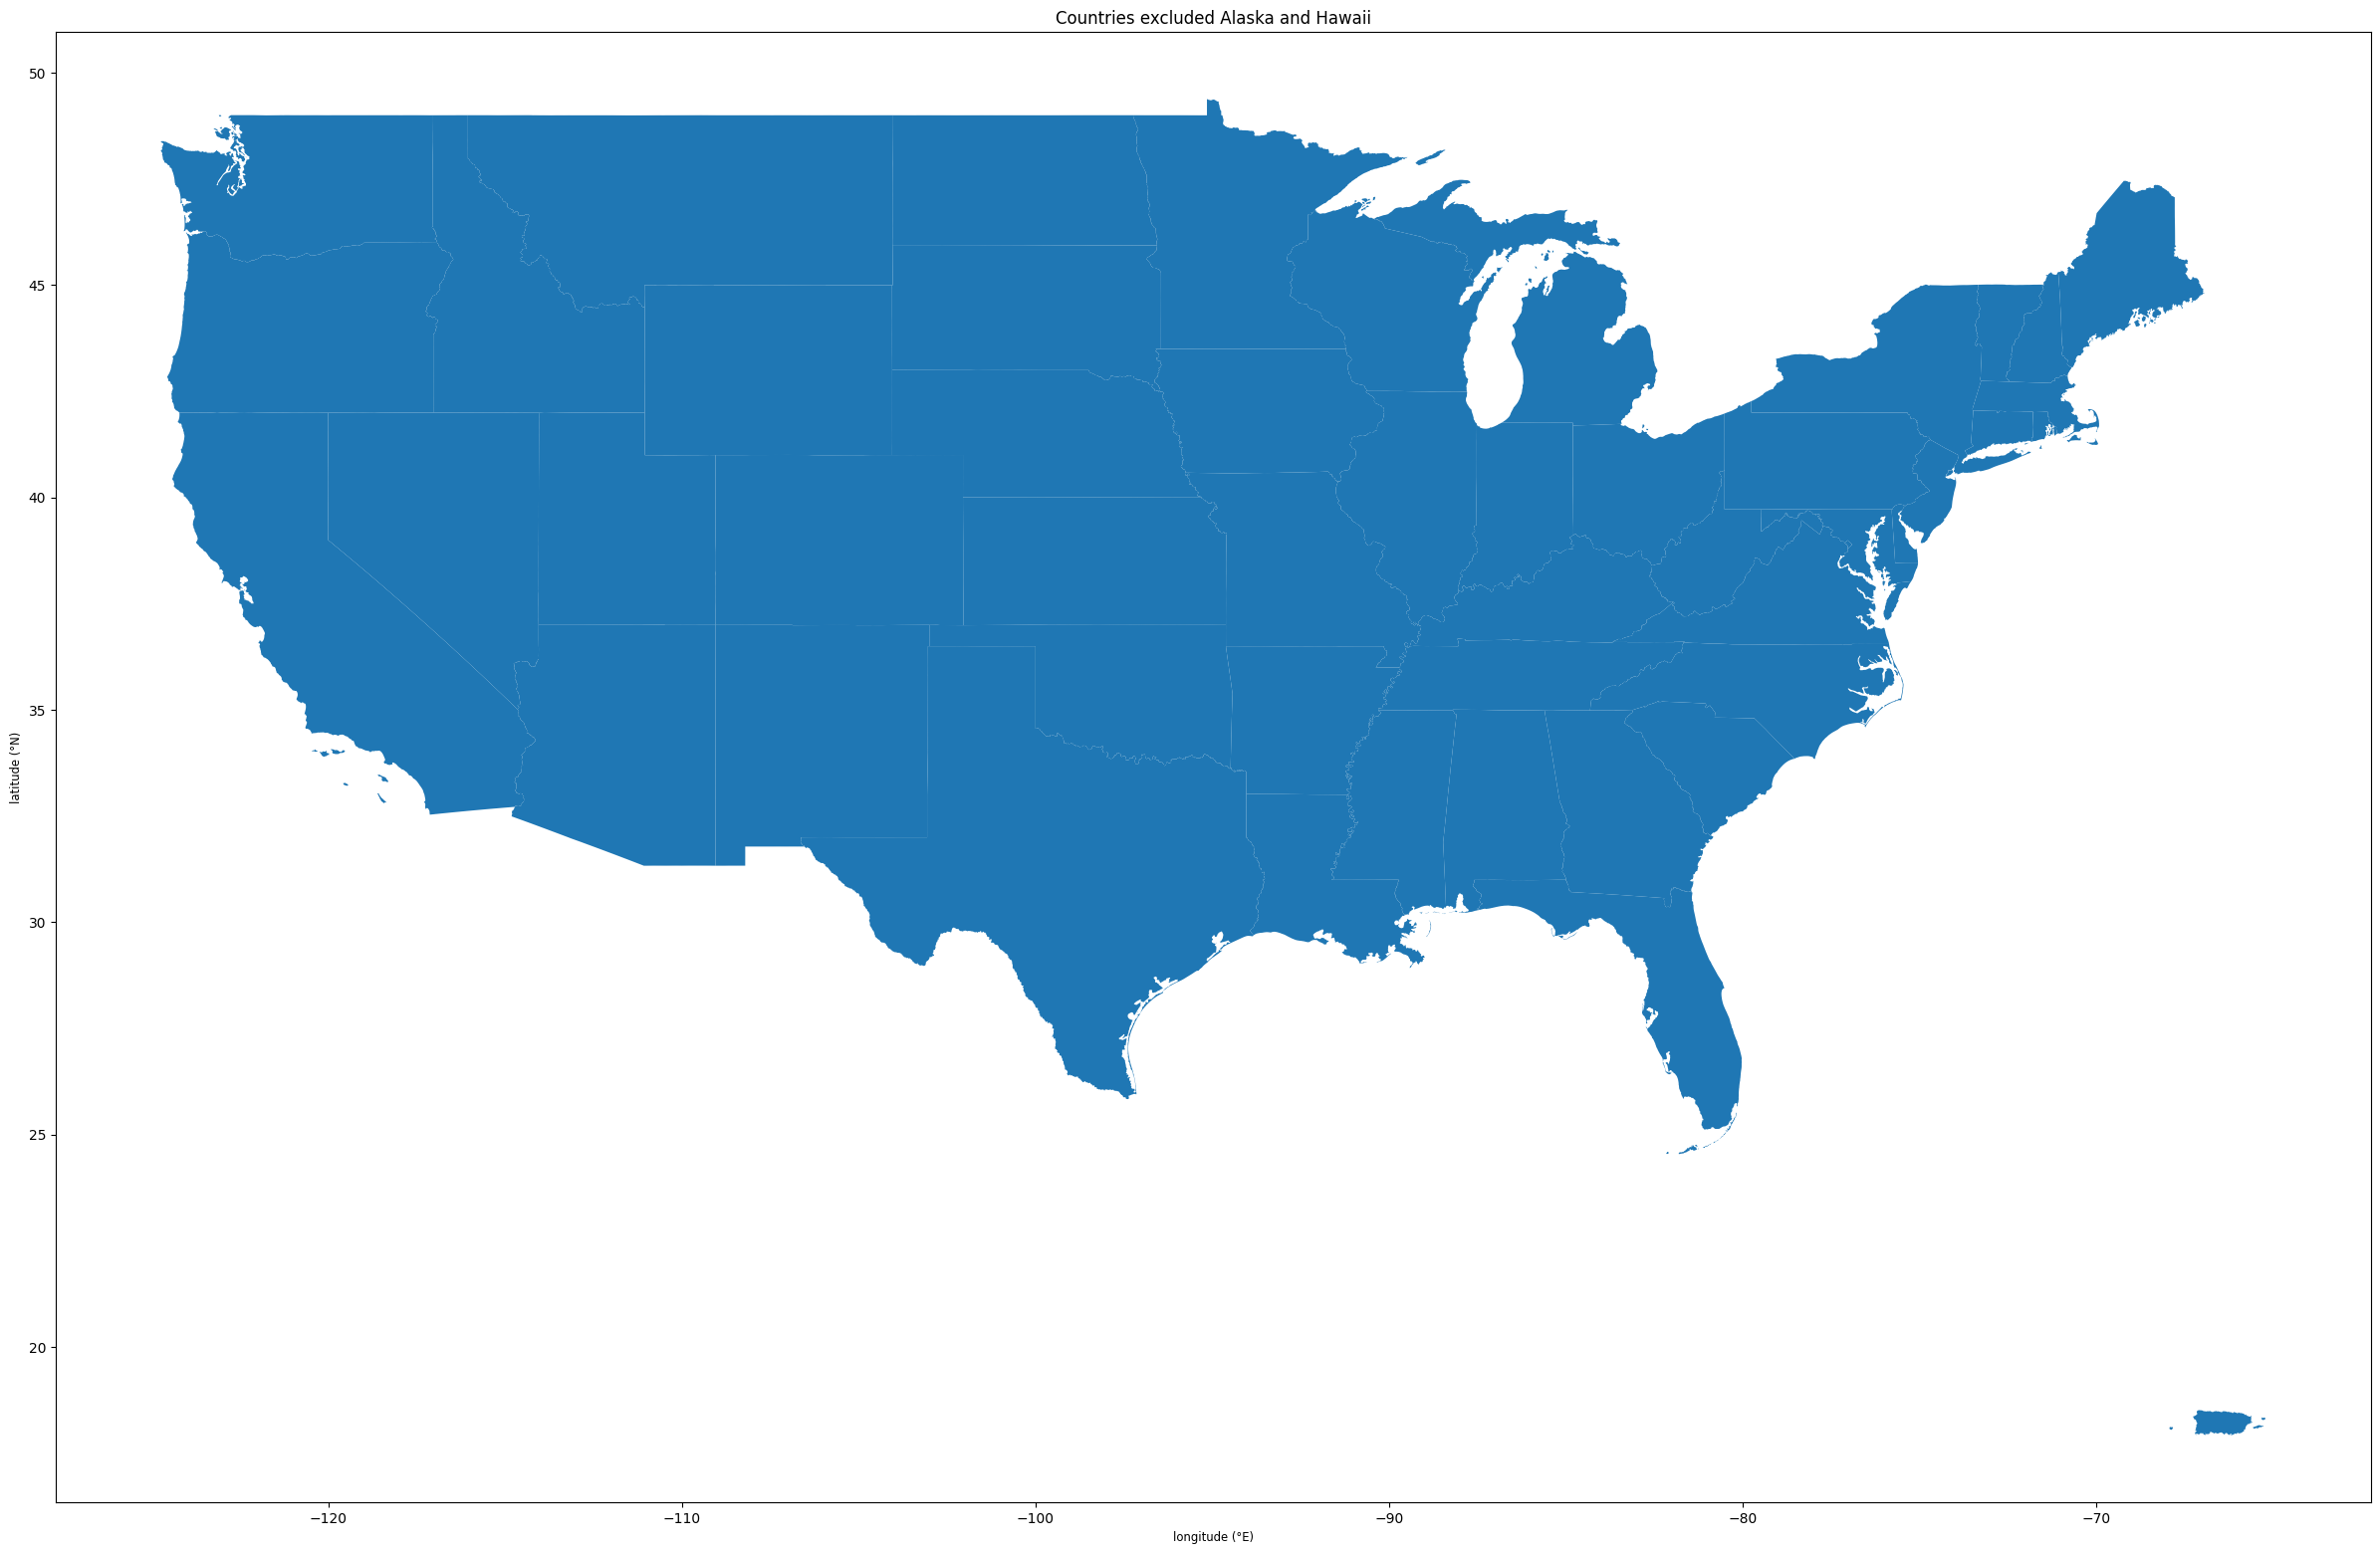

In [10]:
# Plot the US states (Alaska and Hawaii excluded)
country_filtred = country[~country["NAME"].isin(["Alaska", "Hawaii"])]

fig, ax = plt.subplots(figsize=(30, 20))
country_filtred.plot(ax=ax, categorical=True, legend=True, markersize=40)
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Countries excluded Alaska and Hawaii")
plt.show()